# Online Retail 销售分析

请从上到下依次运行代码单元。Excel 路径使用固定的完整路径，因此不依赖 Notebook 的当前工作目录。

# 英国电商交易数据分析

数据来源：UCI Online Retail
https://archive.ics.uci.edu/dataset/352/online%2Bretail

分析问题：2011 年 1—11 月的销售金额主要来自哪些月份、商品和市场？

计算规则：
- 排除订单编号以 C 开头、数量小于等于 0、单价小于等于 0 的记录。
- 排除 M、DOT、POST 三个特殊编号。
- 每行销售金额 = 数量 × 单价。
- 月度、商品和市场分析使用相同的筛选规则。

限制：
- 金额不是利润，未扣除退款。
- 排除三个特殊编号不代表已识别全部非商品项目。
- 商品编号 22502 存在描述不一致。
- 不分析客户画像，也不凭销售趋势直接判断增长原因。

In [1]:
# 1. 导入工具并读取 Excel 数据
from pathlib import Path
import sys
import pandas as pd
import openpyxl

DATA_FILE = Path(r"C:\Users\Lenovo\Desktop\retail analysis\data\raw\Online Retail.xlsx")
print("当前工作目录：", Path.cwd())
print("当前 Python：", sys.executable)
print("pandas：", pd.__version__)
print("openpyxl：", openpyxl.__version__)
if not DATA_FILE.is_file():
    raise FileNotFoundError(f"找不到数据文件：{DATA_FILE}")
df = pd.read_excel(DATA_FILE)
print("原始数据行列：", df.shape)

当前工作目录： C:\Users\Lenovo\Desktop\retail analysis
当前 Python： D:\anancoda\python.exe
pandas： 2.3.3
openpyxl： 3.1.5
原始数据行列： (541909, 8)


In [2]:
# 2. 查看数据内容、字段、类型、缺失值和日期范围
display(df.head())
print("\n字段名：", df.columns.tolist())
print("\n每列缺失值数量：")
display(df.isna().sum().to_frame("缺失值行数"))
print("\n数据类型和非空数量：")
df.info()
print("\n日期范围：", df["InvoiceDate"].min(), "到", df["InvoiceDate"].max())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



字段名： ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

每列缺失值数量：


,缺失值行数
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



数据类型和非空数量：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

日期范围： 2010-12-01 08:26:00 到 2011-12-09 12:50:00


In [3]:
# 3. 检查取消订单、数量和单价异常
is_cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
anomaly_counts = pd.Series({
    "取消订单": is_cancelled.sum(),
    "数量小于或等于 0": (df["Quantity"] <= 0).sum(),
    "单价小于或等于 0": (df["UnitPrice"] <= 0).sum(),
}, name="行数")
display(anomaly_counts.to_frame())

,行数
取消订单,9288
数量小于或等于 0,10624
单价小于或等于 0,2517


In [4]:
# 4. 保留有效销售记录并计算 Revenue
valid_sales = (
    ~is_cancelled
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
)
df_clean = df.loc[valid_sales].copy()
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]
print("清洗前行数：", len(df))
print("清洗后行数：", len(df_clean))
print("排除行数：", len(df) - len(df_clean))
display(df_clean[["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]].head())

清洗前行数： 541909
清洗后行数： 530104
排除行数： 11805


,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [5]:
# 5. 按月汇总销售额并查看销售额最高的月份
df_clean["Month"] = df_clean["InvoiceDate"].dt.strftime("%Y-%m")
monthly_revenue = df_clean.groupby("Month")["Revenue"].sum().sort_index()
display(monthly_revenue.to_frame("Revenue"))
best_month = monthly_revenue.idxmax()
print(f"销售额最高的月份：{best_month}，销售额：{monthly_revenue.loc[best_month]:,.2f}")

,Revenue
Month,
2010-12,823746.140
2011-01,691364.560
2011-02,523631.890
2011-03,717639.360
2011-04,537808.621
2011-05,770536.020
2011-06,761739.900
2011-07,719221.191
2011-08,759138.380


销售额最高的月份：2011-11，销售额：1,509,496.33


In [6]:
print("最早日期：", df["InvoiceDate"].min())
print("最晚日期：", df["InvoiceDate"].max())

最早日期： 2010-12-01 08:26:00
最晚日期： 2011-12-09 12:50:00


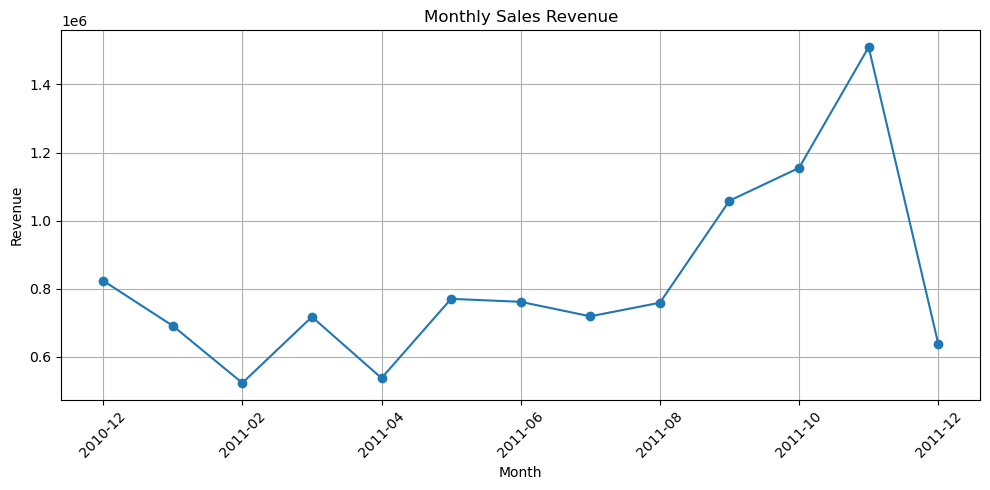

In [7]:
import matplotlib.pyplot as plt

monthly_revenue.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
monthly_2011 = monthly_revenue.loc["2011-01":"2011-11"]

print("最高月份：", monthly_2011.idxmax(), round(monthly_2011.max(), 2))
print("最低月份：", monthly_2011.idxmin(), round(monthly_2011.min(), 2))

最高月份： 2011-11 1509496.33
最低月份： 2011-02 523631.89


按当前清洗口径，2011 年 1—11 月中，11 月销售额最高，2 月最低；11 月约为 2 月的 2.88 倍。这个结果说明两个月的销售额有差异，不能单凭它判断原因。

In [9]:
start = pd.Timestamp("2011-01-01")
end = pd.Timestamp("2011-12-01")

sales_2011 = df_clean[
    (df_clean["InvoiceDate"] >= start)
    & (df_clean["InvoiceDate"] < end)
].copy()

print("保留行数：", len(sales_2011))
print("最早日期：", sales_2011["InvoiceDate"].min())
print("最晚日期：", sales_2011["InvoiceDate"].max())

保留行数： 463513
最早日期： 2011-01-04 10:00:00
最晚日期： 2011-11-30 17:37:00


In [10]:
monthly_sales_2011 = sales_2011.groupby(
    sales_2011["InvoiceDate"].dt.strftime("%Y-%m")
)["Revenue"].sum()

print("月份数：", len(monthly_sales_2011))
print("明细销售额合计：", round(sales_2011["Revenue"].sum(), 2))
print("按月销售额合计：", round(monthly_sales_2011.sum(), 2))
print(monthly_sales_2011.round(2))

月份数： 11
明细销售额合计： 9204145.72
按月销售额合计： 9204145.72
InvoiceDate
2011-01     691364.56
2011-02     523631.89
2011-03     717639.36
2011-04     537808.62
2011-05     770536.02
2011-06     761739.90
2011-07     719221.19
2011-08     759138.38
2011-09    1058590.17
2011-10    1154979.30
2011-11    1509496.33
Name: Revenue, dtype: float64


In [11]:
top_products = (
    sales_2011.groupby("StockCode")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

StockCode
DOT       161704.89
22423     140607.91
47566      97378.11
85123A     91857.03
85099B     88094.00
23166      81448.21
M          75194.46
POST       70906.59
23084      57321.97
84879      52946.32
Name: Revenue, dtype: float64


In [12]:
top_code_names = sales_2011[
    sales_2011["StockCode"].isin(top_products.index)
][["StockCode", "Description"]].drop_duplicates()

top_code_names

,StockCode,Description
42486,85099B,JUMBO BAG RED RETROSPOT
42494,85123A,WHITE HANGING HEART T-LIGHT HOLDER
42651,22423,REGENCY CAKESTAND 3 TIER
42683,84879,ASSORTED COLOUR BIRD ORNAMENT
42750,M,Manual
42842,47566,PARTY BUNTING
42979,DOT,DOTCOM POSTAGE
43431,POST,POSTAGE
61619,23166,MEDIUM CERAMIC TOP STORAGE JAR
183218,23084,RABBIT NIGHT LIGHT


In [13]:
top_code_names["StockCode"] = top_code_names["StockCode"].astype(str)
top_code_names = top_code_names.sort_values("StockCode")
top_code_names

,StockCode,Description
42651,22423,REGENCY CAKESTAND 3 TIER
183218,23084,RABBIT NIGHT LIGHT
61619,23166,MEDIUM CERAMIC TOP STORAGE JAR
42842,47566,PARTY BUNTING
42683,84879,ASSORTED COLOUR BIRD ORNAMENT
42486,85099B,JUMBO BAG RED RETROSPOT
42494,85123A,WHITE HANGING HEART T-LIGHT HOLDER
42979,DOT,DOTCOM POSTAGE
42750,M,Manual
43431,POST,POSTAGE


In [14]:
non_product_codes = ["M", "DOT", "POST"]

sales_goods = sales_2011[
    ~sales_2011["StockCode"].isin(non_product_codes)
].copy()

top_goods = (
    sales_goods.groupby("StockCode")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_goods)

StockCode
22423     140607.91
47566      97378.11
85123A     91857.03
85099B     88094.00
23166      81448.21
23084      57321.97
84879      52946.32
22502      50293.86
22086      48855.78
79321      43971.58
Name: Revenue, dtype: float64


In [15]:
top_goods_names = sales_goods[
    sales_goods["StockCode"].isin(top_goods.index)
][["StockCode", "Description"]].drop_duplicates()

top_goods_names

,StockCode,Description
42486,85099B,JUMBO BAG RED RETROSPOT
42494,85123A,WHITE HANGING HEART T-LIGHT HOLDER
42580,79321,CHILLI LIGHTS
42651,22423,REGENCY CAKESTAND 3 TIER
42683,84879,ASSORTED COLOUR BIRD ORNAMENT
42842,47566,PARTY BUNTING
42966,22502,PICNIC BASKET WICKER SMALL
43230,22086,PAPER CHAIN KIT 50'S CHRISTMAS
61619,23166,MEDIUM CERAMIC TOP STORAGE JAR
183218,23084,RABBIT NIGHT LIGHT


按当前清洗口径并排除已识别的邮费和手工费用后，商品编号 22423（REGENCY CAKESTAND 3 TIER，三层蛋糕架）的销售金额最高，为 140,607.91。这里说的是销售金额，不是利润。

In [16]:
country_revenue = (
    sales_goods.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(country_revenue.head(10).round(2))

Country
United Kingdom    7481365.13
Netherlands        263406.84
EIRE               259030.15
Germany            185266.58
France             169549.51
Australia          137138.46
Spain               53733.17
Switzerland         51862.98
Belgium             34038.70
Sweden              32767.03
Name: Revenue, dtype: float64


In [17]:
total_revenue = country_revenue.sum()

uk_revenue = country_revenue.loc["United Kingdom"]
other_revenue = total_revenue - uk_revenue

uk_share = uk_revenue / total_revenue * 100
other_share = other_revenue / total_revenue * 100

print("全部市场金额：", round(total_revenue, 2))
print("英国金额：", round(uk_revenue, 2))
print("其他市场金额：", round(other_revenue, 2))
print("英国占比：", round(uk_share, 2), "%")
print("其他市场占比：", round(other_share, 2), "%")

全部市场金额： 8896339.78
英国金额： 7481365.13
其他市场金额： 1414974.65
英国占比： 84.09 %
其他市场占比： 15.91 %


In [18]:
print(sales_goods.shape)

(461584, 10)


In [19]:
monthly_goods = sales_goods.groupby(
    sales_goods["InvoiceDate"].dt.strftime("%Y-%m")
)["Revenue"].sum()

print(monthly_goods.round(2))


InvoiceDate
2011-01     672207.41
2011-02     509167.87
2011-03     692235.70
2011-04     516754.79
2011-05     741726.74
2011-06     739426.88
2011-07     689947.74
2011-08     737067.22
2011-09    1031430.36
2011-10    1107449.54
2011-11    1458925.53
Name: Revenue, dtype: float64


In [20]:
print("月份数：", len(monthly_goods))
print("按月合计：", round(monthly_goods.sum(), 2))
print("明细合计：", round(sales_goods["Revenue"].sum(), 2))

月份数： 11
按月合计： 8896339.78
明细合计： 8896339.78


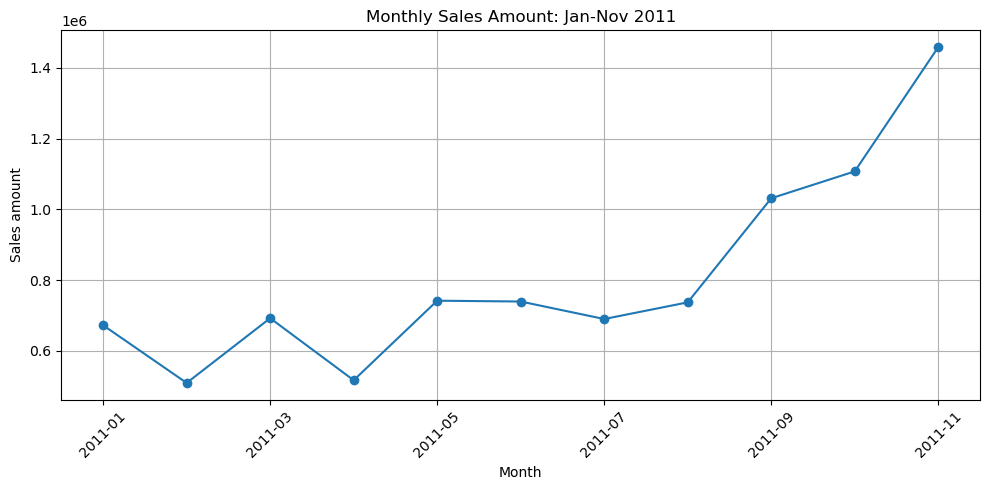

In [21]:
import matplotlib.pyplot as plt
from pathlib import Path

monthly_goods.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Sales Amount: Jan-Nov 2011")
plt.xlabel("Month")
plt.ylabel("Sales amount")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

Path("outputs").mkdir(exist_ok=True)
plt.savefig("outputs/monthly_sales_2011.png", dpi=150)
plt.show()

在排除取消记录、非正数量、非正单价及 M、DOT、POST 三个特殊编号后，2011 年 1—11 月中，11 月销售金额最高，为 1,458,925.53；2 月最低，为 509,167.87。9—11 月销售金额连续上升，但仅凭这张图无法确定增长原因。

In [22]:
print(top_goods)

StockCode
22423     140607.91
47566      97378.11
85123A     91857.03
85099B     88094.00
23166      81448.21
23084      57321.97
84879      52946.32
22502      50293.86
22086      48855.78
79321      43971.58
Name: Revenue, dtype: float64


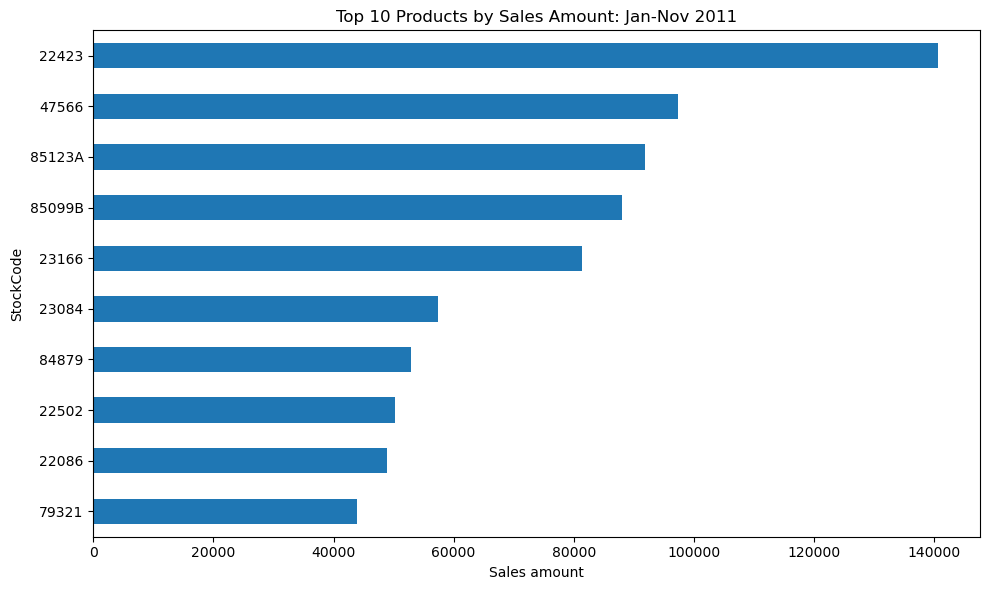

In [23]:
top_goods.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Sales Amount: Jan-Nov 2011")
plt.xlabel("Sales amount")
plt.ylabel("StockCode")
plt.tight_layout()

plt.savefig("outputs/top10_products_2011.png", dpi=150)
plt.show()

在 2011 年 1—11 月、按当前清洗和排除规则统计的商品中，编号 22423（REGENCY CAKESTAND 3 TIER，三层蛋糕架）的销售金额最高，为 140,607.91。这里排名依据是销售金额，不是销售件数。

编号 22502 对应两种不同描述，本项目按商品编号合并统计，尚未确认描述不一致的原因。

In [24]:
market_amounts = pd.Series({
    "United Kingdom": country_revenue.loc["United Kingdom"],
    "Other markets": country_revenue.drop("United Kingdom").sum()
})

print(market_amounts)

United Kingdom    7481365.134
Other markets     1414974.650
dtype: float64


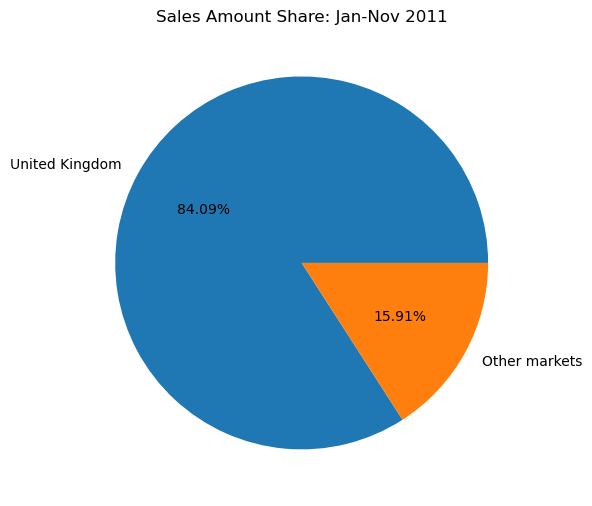

In [25]:
market_amounts.plot(
    kind="pie",
    autopct="%.2f%%",
    figsize=(6, 6)
)

plt.title("Sales Amount Share: Jan-Nov 2011")
plt.ylabel("")
plt.tight_layout()

plt.savefig("outputs/market_share_2011.png", dpi=150)
plt.show()

2011 年 1—11 月，按当前清洗及特殊编号排除规则，全部市场销售金额为 8,896,339.78。其中英国为 7,481,365.13，占 84.09%；其他市场合计为 1,414,974.65，占 15.91%。销售金额主要来自英国市场。
占比的分母是全部市场金额，不是前十个国家的金额。这里计算的是销售金额，不是利润，也未扣除退款。

In [26]:
aus_revenue = country_revenue.loc["Australia"]
print(aus_revenue)

137138.46


In [31]:
aus_share = (aus_revenue / country_revenue.sum()) * 100
print (aus_share)

1.5415155370598868
